# Caldis — A Dynamic Simulation (with time-varying inputs)

The earlier examples were **steady state**: `solve()` finds the one state where every
residual is zero. This notebook runs a **transient** instead: a closed tank of air is
heated, and we watch its temperature and pressure evolve — including when the heater
is **switched off partway through**.

Some components own **state variables** carrying a time derivative (`.der`): here the
fluid's mass `M` and internal energy `U`, and the wall temperature `T`. `simulate()`
**integrates** those state equations step by step instead of solving `R(x)=0` once.

The tank is a **composite**: a fluid control volume (states `M`, `U`) plus a wall
(a thermal mass, state `T`). A heater warms the wall; the wall warms the fluid
through a conductance `UA`. Nothing flows in or out, so the volume is constant and
heating raises the pressure.

In [2]:
# --- imports ---
import numpy as np
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

import caldis
from caldis.core.system import System
from caldis.components import FluidBoundary
from caldis.components.vessels.tank import TankConstV   # composite: fluid volume + wall
from caldis.fluids import CoolPropBackend
from caldis.solvers.dynamic import simulate

## 1. Build the system

`TankConstV` takes its **initial state** (`p_init`, `h_init`, `T_wall_init`), its
volume `V`, and the wall parameters (`C_wall`, `UA_wall`, `Q_heater`). The tank has
two fluid ports (`inl`, `out`); to make it **closed** we cap each with a
`FluidBoundary` carrying **zero mass flow**, so the mass `M` stays constant and only
the energy balance moves.

`Q_heater` here is just the initial value — we will drive it in time in step 2.

In [3]:
be = CoolPropBackend("Air")

p0, T0 = 1.0e5, 293.15                       # initial tank state: 1 bar, 20 C
h0 = PropsSI("H", "P", p0, "T", T0, "Air")

tank = TankConstV("tank", backend=be, V=0.05,     # 50 L rigid volume
                  p_init=p0, h_init=h0,
                  C_wall=800.0,                   # wall heat capacity [J/K]
                  T_wall_init=T0,
                  UA_wall=30.0,                   # wall <-> fluid conductance [W/K]
                  Q_heater=150.0)                 # heater on the wall [W] (initial)

# closed tank: zero flow on both ports (nothing enters or leaves)
feed = FluidBoundary("feed", mdot=0.0, h=h0, backend=be)
cap  = FluidBoundary("cap",  mdot=0.0, backend=be)

sys_ = System("heated_tank")
sys_.add(tank, feed, cap)
sys_.connect(feed.port, tank.inl)
sys_.connect(tank.out, cap.port)

Connection(tank.fluid.out <-> cap.port)

## 2. Drive an input in time — `update_inputs`

`simulate(sys_, t_end, dt, update_inputs=..., init=...)` accepts a callback
**`update_inputs(system, t)`** that it calls at `t = 0` and before every step. Inside
it you set any parameter or boundary spec to its value at time `t` — a heater duty, a
feed flow, an ambient temperature, a set-point… This is how operating conditions vary
during a run.

Here the heater runs at 150 W, then is **switched off at t = 300 s**. Watch the
temperatures rise while it is on, then relax toward each other once it is off.

`init=None` starts from the built initial state (the tank is not at steady state with
the heater on); `init="steady"` would pre-solve a steady state using the same
Newton-first solver as `solve()`.

In [4]:
Qh_on, t_off = 150.0, 300.0      # heater power [W] and switch-off time [s]

def update_inputs(system, t):
    # set the heater duty to its value at time t (step profile: on, then off)
    tank.params["Q_heater"] = Qh_on if t < t_off else 0.0

res = simulate(sys_, t_end=600.0, dt=5.0, update_inputs=update_inputs, init=None)
print("simulated", len(res.time), "time steps up to", res.time[-1], "s")

simulated 121 time steps up to 600.0 s


## 3. Read & plot the time series

`Results` gives each quantity as a time series, addressed by hierarchical name:
`res.tank.fluid.T`, `res.tank.wall.T`, `res.tank.fluid.p`. The wall (directly heated)
leads; the fluid follows through `UA`. After the heater switches off, no energy
enters — wall and fluid converge to a common temperature and the pressure plateaus.

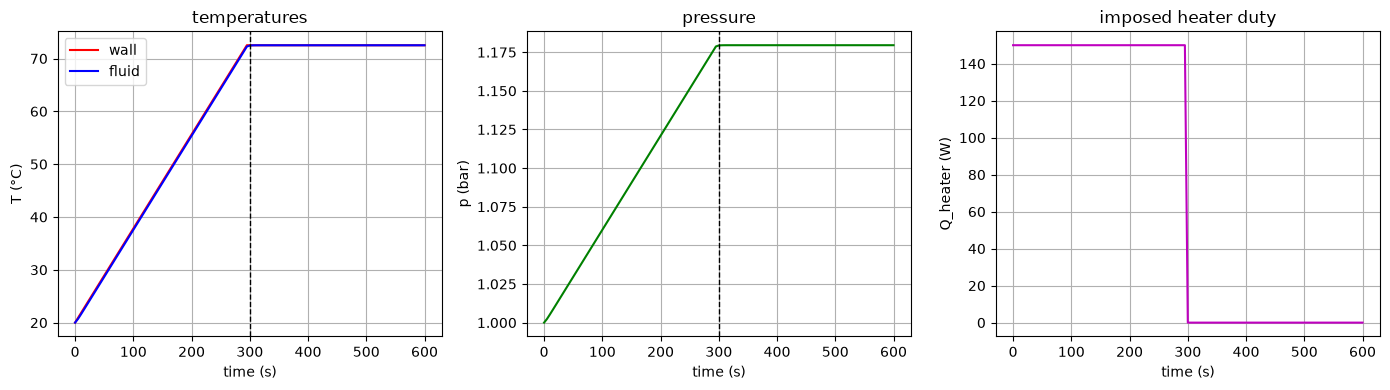

peak fluid T (at t_off) = 72.5 °C
final fluid T = 72.5 °C,  final wall T = 72.5 °C
final p = 1.180 bar  (started 1.000)


In [5]:
t       = res.time
T_fluid = res.tank.fluid.T        # fluid temperature [K]
T_wall  = res.tank.wall.T         # wall temperature  [K]
p_fluid = res.tank.fluid.p        # fluid pressure    [Pa]
Qh      = np.where(t < t_off, Qh_on, 0.0)   # the heater profile we imposed

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(t, T_wall - 273.15, 'r-', label="wall")
ax[0].plot(t, T_fluid - 273.15, 'b-', label="fluid")
ax[0].axvline(t_off, color='k', ls='--', lw=1); ax[0].set_title("temperatures")
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("T (°C)"); ax[0].legend(); ax[0].grid(True)
ax[1].plot(t, p_fluid / 1e5, 'g-')
ax[1].axvline(t_off, color='k', ls='--', lw=1); ax[1].set_title("pressure")
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("p (bar)"); ax[1].grid(True)
ax[2].plot(t, Qh, 'm-'); ax[2].set_title("imposed heater duty")
ax[2].set_xlabel("time (s)"); ax[2].set_ylabel("Q_heater (W)"); ax[2].grid(True)
fig.tight_layout(); plt.show()

print(f"peak fluid T (at t_off) = {np.interp(t_off, t, T_fluid)-273.15:.1f} °C")
print(f"final fluid T = {T_fluid[-1]-273.15:.1f} °C,  final wall T = {T_wall[-1]-273.15:.1f} °C")
print(f"final p = {p_fluid[-1]/1e5:.3f} bar  (started {p0/1e5:.3f})")